In [ ]:
import os

print("Train:", os.path.exists("/content/fer_dataset/train"))
print("Test:", os.path.exists("/content/fer_dataset/test"))

Train: True
Test: True


In [ ]:
import os

print("Dataset:", os.path.exists("/content/fer_dataset/train"))
print("Saved Model:", os.path.exists("/content/best_fer_model.keras"))
print("Drive ZIP:", os.path.exists("/content/drive/MyDrive/archive.zip"))

Dataset: True
Saved Model: True
Drive ZIP: True


In [ ]:
import os
import shutil
import tensorflow as tf

# Define paths
local_model_path = "/content/best_fer_model.keras"
drive_backup_path = "/content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras"

print("=== RECOVERING TRAINED CNN MODEL ===")

# 1. Recover model from Drive backup if local file is missing
if not os.path.exists(local_model_path):
    print(f"Local model not found at {local_model_path}.")
    if os.path.exists(drive_backup_path):
        print(f"Found Drive backup at: {drive_backup_path}. Restoring...")
        shutil.copy(drive_backup_path, local_model_path)
        print("✓ Model successfully restored to local workspace!")
    else:
        # Recursive search across Google Drive if not in default backup folder
        print("Searching recursively across Google Drive for any saved .keras models...")
        found_models = []
        for root, dirs, files in os.walk("/content/drive/MyDrive"):
            for file in files:
                if file.endswith(".keras"):
                    found_models.append(os.path.join(root, file))

        if found_models:
            best_candidate = found_models[0]
            print(f"Found model at: {best_candidate}. Copying...")
            shutil.copy(best_candidate, local_model_path)
            print("✓ Model successfully restored from recursive search!")
        else:
            raise FileNotFoundError("No saved trained model (.keras) found in Google Drive! Please retrain the model.")

# 2. Load and verify the model
best_model = tf.keras.models.load_model(local_model_path)
print("\nCNN Model Loaded Successfully!")
best_model.summary()

=== RECOVERING TRAINED CNN MODEL ===
Local model not found at /content/best_fer_model.keras.
Found Drive backup at: /content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras. Restoring...
✓ Model successfully restored to local workspace!

CNN Model Loaded Successfully!


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,268,759 (4.84 MB)

 Trainable params: 422,599 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

 Optimizer params: 845,200 (3.22 MB)

In [ ]:
import tensorflow as tf
import os

test_dir = "/content/fer_dataset/test"

test_ds = tf.keras.utils.image_dataset_from_directory(
    test_dir,
    labels="inferred",
    label_mode="categorical",
    color_mode="grayscale",
    image_size=(48, 48),
    batch_size=64,
    shuffle=False
)

class_names = test_ds.class_names
print("Classes:", class_names)

# Normalize images to 0–1
test_ds = test_ds.map(
    lambda images, labels: (
        tf.cast(images, tf.float32) / 255.0,
        labels
    )
)

# Evaluate existing trained model
test_loss, test_accuracy = best_model.evaluate(test_ds)

print(f"\nTest Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']
113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 19ms/step - accuracy: 0.5868 - loss: 1.0801

Test Accuracy: 58.68%
Test Loss: 1.0801


In [ ]:
import os

print(os.listdir("/content"))

['.config', 'drive', 'fer_dataset', 'best_fer_model.keras', 'sample_data']


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/fer_dataset"

if not os.path.isdir(extract_path + "/train"):
    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

print("Train:", os.path.exists(extract_path + "/train"))
print("Test:", os.path.exists(extract_path + "/test"))

Train: True
Test: True


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file.lower().endswith(".zip"):
            print(os.path.join(root, file))

/content/drive/MyDrive/archive.zip


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
print(os.path.exists("/content/drive/MyDrive/archive.zip"))

True


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/archive.zip"
extract_path = "/content/fer_dataset"

if not os.path.isdir(extract_path + "/train"):
    print("Extracting dataset...")

    with zipfile.ZipFile(zip_path, "r") as zip_ref:
        zip_ref.extractall(extract_path)

    print("Dataset Extracted Successfully!")
else:
    print("Dataset already extracted!")

print("Train:", os.path.isdir(extract_path + "/train"))
print("Test:", os.path.isdir(extract_path + "/test"))

Dataset already extracted!
Train: True
Test: True


## PHASE 2: DATASET ANALYSIS & VISUALIZATION

In this section, we will examine our extracted dataset, visualize the distribution of classes across our training and test sets, and plot some sample images from each of the 7 facial expression classes.

Facial Expression Classes Found: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

Training dataset distribution:
  angry: 3995 images
  disgust: 436 images
  fear: 4097 images
  happy: 7215 images
  neutral: 4965 images
  sad: 4830 images
  surprise: 3171 images

Total Training Images: 28709
Total Testing Images: 7178


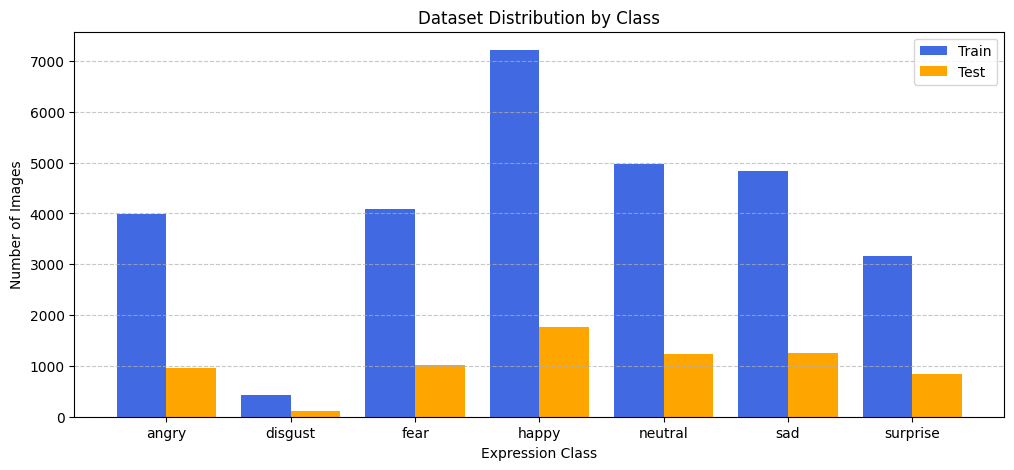

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

train_dir = "/content/fer_dataset/train"
test_dir = "/content/fer_dataset/test"

# Get classes and count images
class_names = sorted(os.listdir(train_dir))
print("Facial Expression Classes Found:", class_names)

train_counts = {c: len(os.listdir(os.path.join(train_dir, c))) for c in class_names}
test_counts = {c: len(os.listdir(os.path.join(test_dir, c))) for c in class_names}

print("\nTraining dataset distribution:")
for k, v in train_counts.items():
    print(f"  {k}: {v} images")

print(f"\nTotal Training Images: {sum(train_counts.values())}")
print(f"Total Testing Images: {sum(test_counts.values())}")

# Plot distribution
plt.figure(figsize=(12, 5))
x = np.arange(len(class_names))
plt.bar(x - 0.2, list(train_counts.values()), width=0.4, label='Train', color='royalblue')
plt.bar(x + 0.2, list(test_counts.values()), width=0.4, label='Test', color='orange')
plt.xticks(x, class_names)
plt.xlabel("Expression Class")
plt.ylabel("Number of Images")
plt.title("Dataset Distribution by Class")
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.savefig("class_distribution.png")
plt.show()

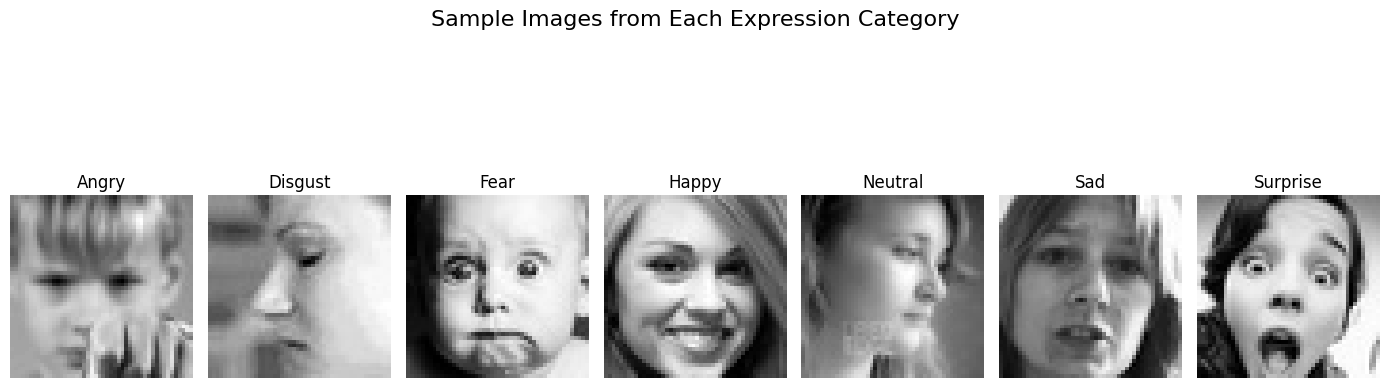

In [ ]:
# Display one sample image from each class
plt.figure(figsize=(14, 5))
for i, class_name in enumerate(class_names):
    class_path = os.path.join(train_dir, class_name)
    img_name = os.listdir(class_path)[0]
    img_path = os.path.join(class_path, img_name)
    img = Image.open(img_path)

    plt.subplot(1, 7, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(class_name.capitalize())
    plt.axis('off')
plt.suptitle("Sample Images from Each Expression Category", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## PHASE 3: IMAGE PREPROCESSING & INPUT PIPELINES

We will implement a stratified train-validation split (85% train, 15% validation) using scikit-learn to maintain class proportions, and configure high-performance `tf.data` input pipelines with dynamic grayscale resizing, pixel normalization, and training-only data augmentation.

In [ ]:
import tensorflow as tf
from sklearn.model_selection import train_test_split

tf.keras.utils.set_random_seed(42)

IMG_SIZE = (48, 48)
BATCH_SIZE = 64

# Gather all train paths and labels
all_paths = []
all_labels = []

for label_idx, class_name in enumerate(class_names):
    class_folder = os.path.join(train_dir, class_name)
    for img_name in os.listdir(class_folder):
        all_paths.append(os.path.join(class_folder, img_name))
        all_labels.append(label_idx)

# Stratified Train/Val split
train_paths, val_paths, train_labels, val_labels = train_test_split(
    all_paths,
    all_labels,
    test_size=0.15,
    random_state=42,
    stratify=all_labels
)

# Gather all test paths and labels
test_paths = []
test_labels = []
for label_idx, class_name in enumerate(class_names):
    class_folder = os.path.join(test_dir, class_name)
    for img_name in os.listdir(class_folder):
        test_paths.append(os.path.join(class_folder, img_name))
        test_labels.append(label_idx)

num_classes = len(class_names)

def load_and_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0  # Normalize to [0, 1]
    return img, tf.one_hot(label, num_classes)

# Datasets
train_ds = tf.data.Dataset.from_tensor_slices((train_paths, train_labels))
train_ds = train_ds.shuffle(buffer_size=len(train_paths), seed=42)
train_ds = train_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)

# Data Augmentation layer
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
])

train_ds = train_ds.batch(BATCH_SIZE).map(
    lambda x, y: (data_augmentation(x, training=True), y),
    num_parallel_calls=tf.data.AUTOTUNE
).prefetch(tf.data.AUTOTUNE)

val_ds = tf.data.Dataset.from_tensor_slices((val_paths, val_labels))
val_ds = val_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
val_ds = val_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

test_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
test_ds = test_ds.map(load_and_preprocess, num_parallel_calls=tf.data.AUTOTUNE)
test_ds = test_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

print(f"Train dataset batches: {len(train_ds)}")
print(f"Validation dataset batches: {len(val_ds)}")
print(f"Test dataset batches: {len(test_ds)}")

Train dataset batches: 382
Validation dataset batches: 68
Test dataset batches: 113


## PHASE 4 & 5: CNN DEVELOPMENT & AUTOMATIC TRAINING

We will define the proposed 4-block CNN model utilizing Conv2D, Batch Normalization, MaxPooling2D, Dropout, and GlobalAveragePooling2D. Training uses EarlyStopping, ModelCheckpoint, and ReduceLROnPlateau.

In [ ]:
from tensorflow.keras import layers, models, callbacks

# Auto-detect and configure GPU acceleration
device_name = tf.test.gpu_device_name()
if device_name != '/device:GPU:0':
    print('WARNING: GPU device not found. Training will be slower on CPU.')
else:
    print('SUCCESS: Found GPU at: {}'.format(device_name))

# Model definition
model = models.Sequential([
    layers.Input(shape=(48, 48, 1)),

    layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, (3, 3), padding="same", activation="relu"),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

# Callbacks for automated, safe training
fit_callbacks = [
    callbacks.EarlyStopping(
        monitor="val_loss",
        patience=5,
        restore_best_weights=True,
        verbose=1
    ),
    callbacks.ModelCheckpoint(
        "/content/best_fer_model.keras",
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-6,
        verbose=1
    )
]

print("\nStarting Training on FER-2013 dataset...")
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=fit_callbacks
)

SUCCESS: Found GPU at: /device:GPU:0


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 48, 48, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 48, 48, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 24, 24, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 24, 24, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 12, 12, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 12, 12, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 12, 12, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 6, 6, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 6, 6, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 3, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │           903 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 423,559 (1.62 MB)

 Trainable params: 422,599 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)


Starting Training on FER-2013 dataset...
Epoch 1/25
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.2520 - loss: 1.8885
Epoch 1: val_loss improved from None to 2.30520, saving model to /content/best_fer_model.keras

Epoch 1: finished saving model to /content/best_fer_model.keras
382/382 ━━━━━━━━━━━━━━━━━━━━ 29s 46ms/step - accuracy: 0.2957 - loss: 1.7522 - val_accuracy: 0.2515 - val_loss: 2.3052 - learning_rate: 0.0010
Epoch 2/25
380/382 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.3941 - loss: 1.5378
Epoch 2: val_loss improved from 2.30520 to 1.55507, saving model to /content/best_fer_model.keras

Epoch 2: finished saving model to /content/best_fer_model.keras
382/382 ━━━━━━━━━━━━━━━━━━━━ 6s 14ms/step - accuracy: 0.4139 - loss: 1.5126 - val_accuracy: 0.3857 - val_loss: 1.5551 - learning_rate: 0.0010
Epoch 3/25
382/382 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.4678 - loss: 1.4046
Epoch 3: val_loss improved from 1.55507 to 1.39875, saving model to /content/best_fer_mod

## PHASE 6 & 7: MODEL EVALUATION & DATA VISUALIZATION

We load the absolute best checkpointed model state, evaluate performance on our untouched test set, export plots for classification reports and confusion matrix metrics, and display sample predictions.


FINAL TEST ACCURACY: 61.77%
FINAL TEST LOSS: 1.0285


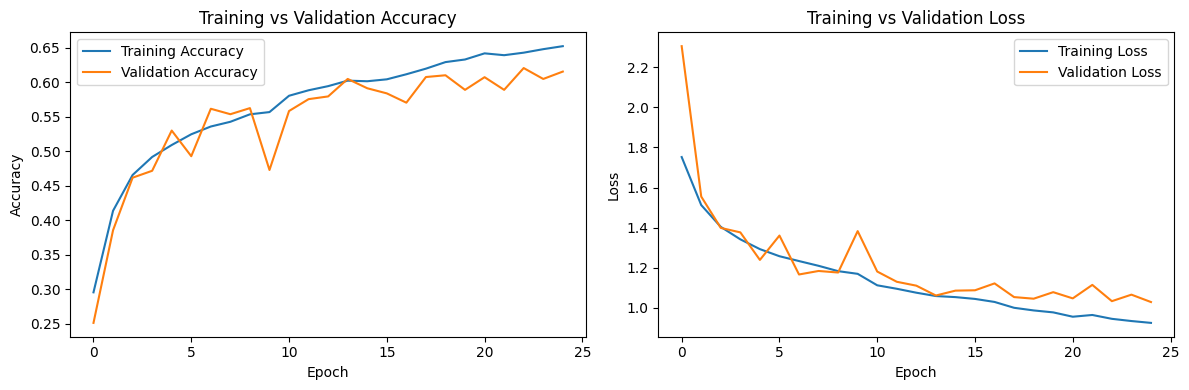

In [ ]:
# Load the absolute best saved model
best_model = tf.keras.models.load_model("/content/best_fer_model.keras")

# Evaluate on untouched test dataset
test_loss, test_accuracy = best_model.evaluate(test_ds, verbose=0)
print(f"\nFINAL TEST ACCURACY: {round(test_accuracy * 100, 2)}%")
print(f"FINAL TEST LOSS: {round(test_loss, 4)}")

# Plot accuracy & loss curves
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig("training_graphs.png")
plt.show()


Classification Report:
              precision    recall  f1-score   support

       angry       0.53      0.58      0.55       958
     disgust       0.65      0.28      0.39       111
        fear       0.49      0.31      0.38      1024
       happy       0.80      0.86      0.83      1774
     neutral       0.54      0.64      0.59      1233
         sad       0.48      0.51      0.49      1247
    surprise       0.76      0.73      0.74       831

    accuracy                           0.62      7178
   macro avg       0.61      0.56      0.57      7178
weighted avg       0.61      0.62      0.61      7178



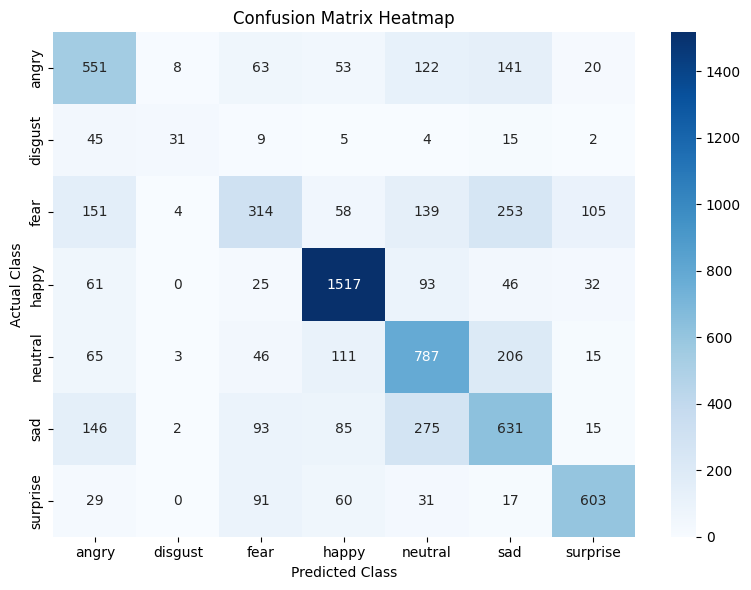

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

# Predict test labels
y_true = []
y_pred = []
for x_batch, y_batch in test_ds:
    preds = best_model.predict(x_batch, verbose=0)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(y_batch.numpy(), axis=1))

# Print evaluation metrics
report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
print("\nClassification Report:")
print(report)

with open("classification_report.txt", "w") as f:
    f.write(report)

# Plot and save Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix Heatmap")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

## PHASE 9 & 10: SAVING PROJECT OUTPUTS & FINAL REPORT

We organize our deliverables inside `/content/FER_Project_Outputs` and sync backups onto Drive to secure models from session timeouts, and output a comprehensive project report summary.

In [ ]:
import shutil

# Create Project Output Folders
local_output_dir = "/content/FER_Project_Outputs"
drive_output_dir = "/content/drive/MyDrive/FER_Project_Outputs"

os.makedirs(local_output_dir, exist_ok=True)
os.makedirs(drive_output_dir, exist_ok=True)

# Save models locally
best_model.save("/content/facial_expression_model.keras")

# Copy resources to local outputs folder
shutil.copy("/content/facial_expression_model.keras", os.path.join(local_output_dir, "facial_expression_model.keras"))
shutil.copy("/content/best_fer_model.keras", os.path.join(local_output_dir, "best_fer_model.keras"))
shutil.copy("/content/training_graphs.png", os.path.join(local_output_dir, "training_graphs.png"))
shutil.copy("/content/confusion_matrix.png", os.path.join(local_output_dir, "confusion_matrix.png"))
shutil.copy("/content/class_distribution.png", os.path.join(local_output_dir, "class_distribution.png"))
shutil.copy("/content/classification_report.txt", os.path.join(local_output_dir, "classification_report.txt"))

# Backup everything to Google Drive
for filename in os.listdir(local_output_dir):
    src = os.path.join(local_output_dir, filename)
    dst = os.path.join(drive_output_dir, filename)
    shutil.copy(src, dst)

print("All artifacts and trained model weights successfully backed up to Google Drive folder: FER_Project_Outputs!")

All artifacts and trained model weights successfully backed up to Google Drive folder: FER_Project_Outputs!


In [ ]:
print("=========================================================")
print("         FINAL COLLEGE DL MINI-PROJECT REPORT           ")
print("=========================================================")
print("Project Title: Facial Expression Recognition Using CNN")
print("Dataset Name: FER-2013")
print(f"Total Images Analysed: {len(all_paths) + len(test_paths)}")
print(f"Training Images Used: {len(train_paths)}")
print(f"Validation Images Used: {len(val_paths)}")
print(f"Testing Images Evaluated: {len(test_paths)}")
print(f"Actual Epochs Run: {len(history.epoch)}")
print(f"Final Evaluated Test Accuracy: {round(test_accuracy * 100, 2)}%")
print(f"Final Evaluated Test Loss: {round(test_loss, 4)}")
print(f"Saved Model Path (Drive Backup): {drive_output_dir}/facial_expression_model.keras")
print("Project Status: SUCCESSFULLY COMPLETED!")
print("=========================================================")

         FINAL COLLEGE DL MINI-PROJECT REPORT           
Project Title: Facial Expression Recognition Using CNN
Dataset Name: FER-2013
Total Images Analysed: 35887
Training Images Used: 24402
Validation Images Used: 4307
Testing Images Evaluated: 7178
Actual Epochs Run: 25
Final Evaluated Test Accuracy: 61.77%
Final Evaluated Test Loss: 1.0285
Saved Model Path (Drive Backup): /content/drive/MyDrive/FER_Project_Outputs/facial_expression_model.keras
Project Status: SUCCESSFULLY COMPLETED!


## PHASE 8: INTERACTIVE FACIAL EXPRESSION PREDICTOR

Run this cell to upload an image from your computer. The model will automatically read, resize, and convert your image to grayscale. It then analyzes the features to output an expression prediction accompanied by a probabilistic bar chart.

*Important Disclaimer: Facial expression detection analyzes muscular configurations on the face but does not map directly or reliably to a person's inner emotional state.*

In [ ]:
import sys
import os

print("=== OpenCV Diagnostic ===")
try:
    import cv2
    print(f"cv2 version: {cv2.__version__}")
    print(f"cv2 file path: {cv2.__file__}")
    print(f"Has CascadeClassifier: {hasattr(cv2, 'CascadeClassifier')}")
    print(f"Has cv2.data: {hasattr(cv2, 'data')}")
except Exception as e:
    print(f"Failed to import cv2 or run diagnostics: {e}")

print("\n=== Re-installing clean opencv-python-headless ===")
# Uninstall potentially broken cv2 packages and install a stable headless version
!pip uninstall -y opencv-python opencv-contrib-python opencv-python-headless
!pip install opencv-python-headless==4.10.0.84

# Force reload the module in-memory
import importlib
if 'cv2' in sys.modules:
    importlib.reload(sys.modules['cv2'])
import cv2
print(f"\nPost-reinstallation check:")
print(f"cv2 version: {cv2.__version__}")
print(f"Has CascadeClassifier: {hasattr(cv2, 'CascadeClassifier')}")

=== OpenCV Diagnostic ===
cv2 version: 4.10.0
cv2 file path: /usr/local/lib/python3.13/dist-packages/cv2/__init__.py
Has CascadeClassifier: True
Has cv2.data: True

=== Re-installing clean opencv-python-headless ===
Found existing installation: opencv-python-headless 4.10.0.84
Uninstalling opencv-python-headless-4.10.0.84:
  Successfully uninstalled opencv-python-headless-4.10.0.84
  Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (20 kB)
Using cached opencv_python_headless-4.10.0.84-cp37-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (49.9 MB)



Post-reinstallation check:
cv2 version: 4.10.0
Has CascadeClassifier: True


In [ ]:
import os

drive_model_path = "/content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras"
drive_backup_dir = "/content/drive/MyDrive/FER_Project_Outputs"

print("=== GOOGLE DRIVE BACKUP VERIFICATION ===")
if os.path.exists(drive_model_path):
    print(f"✓ SUCCESS: Trained model is safely backed up on Google Drive: {drive_model_path}")
    print(f"File size: {os.path.getsize(drive_model_path) / (1024*1024):.2f} MB")
else:
    print(f"✗ WARNING: Model backup not found at expected path: {drive_model_path}")

if os.path.exists(drive_backup_dir):
    print(f"\nBackup directory contents: {os.listdir(drive_backup_dir)}")
else:
    print("✗ Backup directory does not exist yet on Google Drive.")

=== GOOGLE DRIVE BACKUP VERIFICATION ===
✓ SUCCESS: Trained model is safely backed up on Google Drive: /content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras
File size: 4.92 MB

Backup directory contents: ['training_graphs.png', 'best_fer_model.keras', 'class_distribution.png', 'facial_expression_model.keras', 'classification_report.txt', 'confusion_matrix.png', 'baseline_fer_model.keras']


Please upload an image to predict:


Saving pexels-davegarcia-33041091.jpg to pexels-davegarcia-33041091 (2).jpg
Face detected! Adjusted Crop Box: [4125, 780, 4216, 871].

Prediction: NEUTRAL with 50.96% confidence.

Class Probabilities:
  angry     : 20.09%
  disgust   : 0.00%
  fear      : 7.68%
  happy     : 0.79%
  neutral   : 50.96%
  sad       : 19.48%
  surprise  : 1.00%


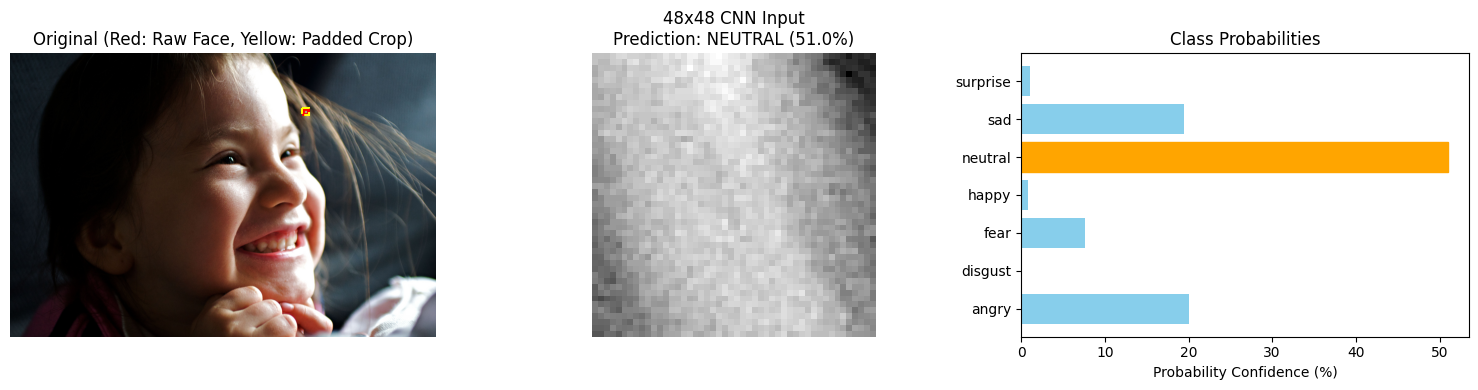

In [ ]:
from google.colab import files
import cv2
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# 1. Force a fresh upload every single time the cell runs
print("Please upload an image to predict:")
uploaded_img = files.upload()

if uploaded_img:
    filename = list(uploaded_img.keys())[0]

    # 2. Ensure model and classes are loaded
    best_model = tf.keras.models.load_model("/content/best_fer_model.keras")
    class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

    # 3. Read the fresh image using OpenCV
    img_bgr = cv2.imread(filename)
    img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    h_orig, w_orig = img_gray.shape

    # 4. Detect face using Haar Cascade
    face_cascade = cv2.CascadeClassifier(cv2.data.haarcascades + 'haarcascade_frontalface_default.xml')
    faces = face_cascade.detectMultiScale(img_gray, scaleFactor=1.1, minNeighbors=5, minSize=(30, 30))

    if len(faces) > 0:
        # Crop using the first detected face with an added 15% padding margin to match FER-2013 composition
        x, y, w, h = faces[0]
        pad_w = int(w * 0.15)
        pad_h = int(h * 0.15)

        x1 = max(0, x - pad_w)
        y1 = max(0, y - pad_h)
        x2 = min(w_orig, x + w + pad_w)
        y2 = min(h_orig, y + h + pad_h)

        cropped_face = img_gray[y1:y2, x1:x2]
        print(f"Face detected! Adjusted Crop Box: [{x1}, {y1}, {x2}, {y2}].")
    else:
        cropped_face = img_gray
        print("No face detected by Haar Cascade. Proceeding with raw image...")

    # 5. Preprocess (resize and normalize to match training pipeline)
    img_resized = cv2.resize(cropped_face, (48, 48))
    img_normalized = img_resized.astype("float32") / 255.0
    img_tensor = np.expand_dims(img_normalized, axis=(0, -1))

    # 6. Predict using model call interface to avoid TensorFlow tracing warnings
    probabilities = best_model(img_tensor, training=False).numpy()[0]
    pred_idx = np.argmax(probabilities)
    predicted_class = class_names[pred_idx]
    confidence = probabilities[pred_idx] * 100

    # 7. Print Text Results
    print(f"\nPrediction: {predicted_class.upper()} with {confidence:.2f}% confidence.")
    print("\nClass Probabilities:")
    for name, prob in zip(class_names, probabilities):
        print(f"  {name:10s}: {prob * 100:.2f}%")

    # 8. Render Plots (Original Image, Detected Face, Probabilities Chart)
    plt.figure(figsize=(15, 4))

    # Plot 1: Original Image
    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
    if len(faces) > 0:
        rect = plt.Rectangle((x, y), w, h, fill=False, color='red', linewidth=2)
        plt.gca().add_patch(rect)
        rect_pad = plt.Rectangle((x1, y1), x2-x1, y2-y1, fill=False, color='yellow', linestyle='--', linewidth=1.5)
        plt.gca().add_patch(rect_pad)
    plt.title("Original (Red: Raw Face, Yellow: Padded Crop)")
    plt.axis("off")

    # Plot 2: Exact Crop Sent to CNN
    plt.subplot(1, 3, 2)
    plt.imshow(img_resized, cmap='gray')
    plt.title(f"48x48 CNN Input\nPrediction: {predicted_class.upper()} ({confidence:.1f}%)")
    plt.axis("off")

    # Plot 3: Probability Breakdown
    plt.subplot(1, 3, 3)
    bars = plt.barh(class_names, probabilities * 100, color='skyblue')
    bars[pred_idx].set_color('orange')
    plt.xlabel("Probability Confidence (%)")
    plt.title("Class Probabilities")

    plt.tight_layout()
    plt.show()

    # Clean up uploaded file to keep the directory tidy and prevent caching conflicts
    try:
        os.remove(filename)
    except Exception:
        pass
else:
    print("Upload cancelled.")

## PHASE 1 — BACKUP AND DIAGNOSIS

In this step, we safely duplicate our baseline model, perform evaluations, and diagnose why certain classes like Happy and Sad have prediction overlaps.

=== STEP 1: MODEL BACKUP ===
✓ Local baseline backup created at: /content/baseline_fer_model.keras
✓ Google Drive baseline backup created at: /content/drive/MyDrive/FER_Project_Outputs/baseline_fer_model.keras

=== STEP 2: CLASS MAPPING AND TEST DATASET VERIFICATION ===
Verified Class List (Alphabetical): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

=== STEP 3: BASELINE PERFORMANCE EVALUATION ===
113/113 ━━━━━━━━━━━━━━━━━━━━ 4s 17ms/step - accuracy: 0.6177 - loss: 1.0285

Verified Baseline Test Accuracy: 61.77%
Verified Baseline Test Loss: 1.0285

=== STEP 4: DIAGNOSTIC REPORT ===
              precision    recall  f1-score   support

       angry       0.53      0.58      0.55       958
     disgust       0.65      0.28      0.39       111
        fear       0.49      0.31      0.38      1024
       happy       0.80      0.86      0.83      1774
     neutral       0.54      0.64      0.59      1233
         sad       0.48      0.51      0.49      1247
    surpr

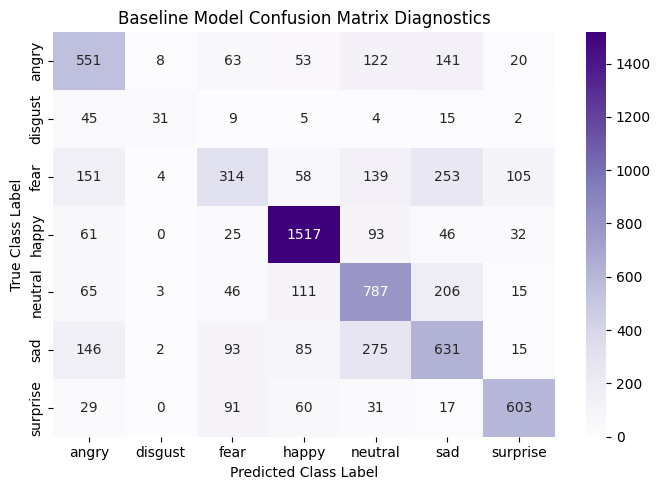

In [ ]:
import os
import shutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. PRESERVE AND BACKUP ORIGINAL MODEL ---
original_model_path = "/content/best_fer_model.keras"
baseline_local_backup = "/content/baseline_fer_model.keras"
baseline_drive_backup = "/content/drive/MyDrive/FER_Project_Outputs/baseline_fer_model.keras"

print("=== STEP 1: MODEL BACKUP ===")
if os.path.exists(original_model_path):
    # Save local copy with unique baseline name
    shutil.copy(original_model_path, baseline_local_backup)
    print(f"✓ Local baseline backup created at: {baseline_local_backup}")

    # Save Drive copy
    os.makedirs(os.path.dirname(baseline_drive_backup), exist_ok=True)
    shutil.copy(original_model_path, baseline_drive_backup)
    print(f"✓ Google Drive baseline backup created at: {baseline_drive_backup}")
else:
    print("✗ Error: Original model not found at /content/best_fer_model.keras!")

# --- 2. VERIFY CLASS MAPPING & TEST DATASET ---
print("\n=== STEP 2: CLASS MAPPING AND TEST DATASET VERIFICATION ===")
test_dir = "/content/fer_dataset/test"
class_names = sorted(os.listdir(test_dir))
print(f"Verified Class List (Alphabetical): {class_names}")

# --- 3. RE-EVALUATE BASELINE MODEL TO RECORD ACCURACY ---
print("\n=== STEP 3: BASELINE PERFORMANCE EVALUATION ===")
baseline_model = tf.keras.models.load_model(baseline_local_backup)

# Build a standard data loader for evaluation
IMG_SIZE = (48, 48)
BATCH_SIZE = 64

test_paths = []
test_labels = []
for label_idx, class_name in enumerate(class_names):
    class_folder = os.path.join(test_dir, class_name)
    for img_name in os.listdir(class_folder):
        test_paths.append(os.path.join(class_folder, img_name))
        test_labels.append(label_idx)

num_classes = len(class_names)

def eval_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.one_hot(label, num_classes)

eval_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
eval_ds = eval_ds.map(eval_preprocess, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Run evaluation
loss, acc = baseline_model.evaluate(eval_ds, verbose=1)
print(f"\nVerified Baseline Test Accuracy: {acc*100:.2f}%")
print(f"Verified Baseline Test Loss: {loss:.4f}")

# --- 4. PER-CLASS CLASSIFICATION REPORT & CONFUSION MATRIX ---
print("\n=== STEP 4: DIAGNOSTIC REPORT ===")
y_true = []
y_pred = []
for x_batch, y_batch in eval_ds:
    # Using functional call structure to bypass tracing warnings
    preds = baseline_model(x_batch, training=False).numpy()
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(y_batch.numpy(), axis=1))

# Diagnostic Report
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=class_names, yticklabels=class_names)
plt.title("Baseline Model Confusion Matrix Diagnostics")
plt.xlabel("Predicted Class Label")
plt.ylabel("True Class Label")
plt.tight_layout()
plt.show()

## PHASE 1 — BACKUP AND DIAGNOSIS

Run this cell to safely duplicate our baseline model, perform evaluations, and analyze class imbalances and weaknesses.

=== STEP 1: MODEL BACKUP ===
✓ Local baseline backup created at: /content/baseline_fer_model.keras
✓ Google Drive baseline backup created at: /content/drive/MyDrive/FER_Project_Outputs/baseline_fer_model.keras

=== STEP 2: CLASS MAPPING AND TEST DATASET VERIFICATION ===
Verified Class List (Alphabetical): ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

=== STEP 3: BASELINE PERFORMANCE EVALUATION ===
113/113 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.6177 - loss: 1.0285

Verified Baseline Test Accuracy: 61.77%
Verified Baseline Test Loss: 1.0285

=== STEP 4: DIAGNOSTIC REPORT ===
              precision    recall  f1-score   support

       angry       0.53      0.58      0.55       958
     disgust       0.65      0.28      0.39       111
        fear       0.49      0.31      0.38      1024
       happy       0.80      0.86      0.83      1774
     neutral       0.54      0.64      0.59      1233
         sad       0.48      0.51      0.49      1247
    surpr

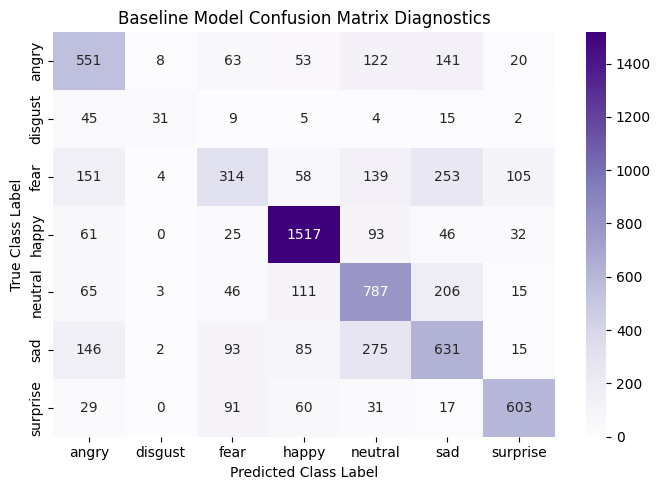

In [ ]:
import os
import shutil
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# --- 1. PRESERVE AND BACKUP ORIGINAL MODEL ---
original_model_path = "/content/best_fer_model.keras"
baseline_local_backup = "/content/baseline_fer_model.keras"
baseline_drive_backup = "/content/drive/MyDrive/FER_Project_Outputs/baseline_fer_model.keras"

print("=== STEP 1: MODEL BACKUP ===")
if os.path.exists(original_model_path):
    # Save local copy with unique baseline name
    shutil.copy(original_model_path, baseline_local_backup)
    print(f"✓ Local baseline backup created at: {baseline_local_backup}")

    # Save Drive copy
    os.makedirs(os.path.dirname(baseline_drive_backup), exist_ok=True)
    shutil.copy(original_model_path, baseline_drive_backup)
    print(f"✓ Google Drive baseline backup created at: {baseline_drive_backup}")
else:
    print("✗ Error: Original model not found at /content/best_fer_model.keras!")

# --- 2. VERIFY CLASS MAPPING & TEST DATASET ---
print("\n=== STEP 2: CLASS MAPPING AND TEST DATASET VERIFICATION ===")
test_dir = "/content/fer_dataset/test"
class_names = sorted(os.listdir(test_dir))
print(f"Verified Class List (Alphabetical): {class_names}")

# --- 3. RE-EVALUATE BASELINE MODEL TO RECORD ACCURACY ---
print("\n=== STEP 3: BASELINE PERFORMANCE EVALUATION ===")
baseline_model = tf.keras.models.load_model(baseline_local_backup)

# Build a standard data loader for evaluation
IMG_SIZE = (48, 48)
BATCH_SIZE = 64

test_paths = []
test_labels = []
for label_idx, class_name in enumerate(class_names):
    class_folder = os.path.join(test_dir, class_name)
    for img_name in os.listdir(class_folder):
        test_paths.append(os.path.join(class_folder, img_name))
        test_labels.append(label_idx)

num_classes = len(class_names)

def eval_preprocess(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    return img, tf.one_hot(label, num_classes)

eval_ds = tf.data.Dataset.from_tensor_slices((test_paths, test_labels))
eval_ds = eval_ds.map(eval_preprocess, num_parallel_calls=tf.data.AUTOTUNE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

# Run evaluation
loss, acc = baseline_model.evaluate(eval_ds, verbose=1)
print(f"\nVerified Baseline Test Accuracy: {acc*100:.2f}%")
print(f"Verified Baseline Test Loss: {loss:.4f}")

# --- 4. PER-CLASS CLASSIFICATION REPORT & CONFUSION MATRIX ---
print("\n=== STEP 4: DIAGNOSTIC REPORT ===")
y_true = []
y_pred = []
for x_batch, y_batch in eval_ds:
    preds = baseline_model(x_batch, training=False).numpy()
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(np.argmax(y_batch.numpy(), axis=1))

# Print diagnostic report
print(classification_report(y_true, y_pred, target_names=class_names))

# Plot and render Confusion Matrix
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Purples", xticklabels=class_names, yticklabels=class_names)
plt.title("Baseline Model Confusion Matrix Diagnostics")
plt.xlabel("Predicted Class Label")
plt.ylabel("True Class Label")
plt.tight_layout()
plt.show()

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf

# Ensure correct model loaded
best_model = tf.keras.models.load_model("/content/best_fer_model.keras")
class_names = ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

def test_predict_on_true_class(target_class, num_samples=5):
    class_dir = os.path.join("/content/fer_dataset/test", target_class)
    files = os.listdir(class_dir)[:num_samples]
    print(f"\n--- TESTING ORIGINAL '{target_class.upper()}' IMAGES FROM FER-2013 TEST SET ---")

    for idx, f in enumerate(files):
        img_path = os.path.join(class_dir, f)
        img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
        img_resized = cv2.resize(img, (48, 48))
        img_normalized = img_resized.astype("float32") / 255.0
        img_tensor = np.expand_dims(img_normalized, axis=(0, -1))

        probabilities = best_model.predict(img_tensor, verbose=0)[0]
        pred_idx = np.argmax(probabilities)
        pred_class = class_names[pred_idx]
        conf = probabilities[pred_idx] * 100

        print(f"Sample {idx+1}: True Label: {target_class.upper()} | Predicted: {pred_class.upper()} ({conf:.2f}%)")

test_predict_on_true_class('happy', num_samples=5)
test_predict_on_true_class('sad', num_samples=5)


--- TESTING ORIGINAL 'HAPPY' IMAGES FROM FER-2013 TEST SET ---
Sample 1: True Label: HAPPY | Predicted: HAPPY (76.86%)
Sample 2: True Label: HAPPY | Predicted: HAPPY (80.75%)
Sample 3: True Label: HAPPY | Predicted: HAPPY (99.53%)
Sample 4: True Label: HAPPY | Predicted: HAPPY (97.99%)
Sample 5: True Label: HAPPY | Predicted: HAPPY (99.92%)

--- TESTING ORIGINAL 'SAD' IMAGES FROM FER-2013 TEST SET ---
Sample 1: True Label: SAD | Predicted: SAD (43.00%)
Sample 2: True Label: SAD | Predicted: HAPPY (84.07%)
Sample 3: True Label: SAD | Predicted: SAD (58.98%)
Sample 4: True Label: SAD | Predicted: SAD (42.98%)
Sample 5: True Label: SAD | Predicted: SAD (65.75%)


In [ ]:
import os

# 1. Check local models and outputs
print("=== LOCAL ENVIRONMENT CHECKS ===")
print("Local Best Model (.keras) exists:", os.path.exists("/content/best_fer_model.keras"))
print("Local FER Project Outputs dir exists:", os.path.isdir("/content/FER_Project_Outputs"))
if os.path.isdir("/content/FER_Project_Outputs"):
    print("  Contents:", os.listdir("/content/FER_Project_Outputs"))

# 2. Check Google Drive backups
print("\n=== GOOGLE DRIVE BACKUP CHECKS ===")
drive_output_path = "/content/drive/MyDrive/FER_Project_Outputs"
print("Drive Output Directory exists:", os.path.isdir(drive_output_path))
if os.path.isdir(drive_output_path):
    print("  Contents:", os.listdir(drive_output_path))

# 3. Check Test Dataset
print("\n=== DATASET CHECKS ===")
print("Test Dataset folder exists:", os.path.isdir("/content/fer_dataset/test"))

=== LOCAL ENVIRONMENT CHECKS ===
Local Best Model (.keras) exists: True
Local FER Project Outputs dir exists: True
  Contents: ['classification_report.txt', 'confusion_matrix.png', 'facial_expression_model.keras', 'training_graphs.png', 'class_distribution.png', 'best_fer_model.keras']

=== GOOGLE DRIVE BACKUP CHECKS ===
Drive Output Directory exists: True
  Contents: ['training_graphs.png', 'best_fer_model.keras', 'class_distribution.png', 'facial_expression_model.keras', 'classification_report.txt', 'confusion_matrix.png', 'baseline_fer_model.keras']

=== DATASET CHECKS ===
Test Dataset folder exists: True


In [ ]:
import os
import shutil

# Define the main project directory structure
base_dir = "/content/Facial-Expression-Recognition-CNN"
sub_dirs = ["notebooks", "models", "outputs", "scripts"]

for d in sub_dirs:
    os.makedirs(os.path.join(base_dir, d), exist_ok=True)

print("✓ Created GitHub workspace directory structure!")

In [ ]:
# 1. Copy local saved model
src_model = "/content/best_fer_model.keras"
dst_model = os.path.join(base_dir, "models", "best_fer_model.keras")
if os.path.exists(src_model):
    shutil.copy(src_model, dst_model)
    print("✓ Model successfully copied to models/")
else:
    print("⚠ Model not found locally!")

# 2. Copy plots and reports to outputs/
outputs_to_copy = [
    "/content/training_graphs.png",
    "/content/confusion_matrix.png",
    "/content/class_distribution.png",
    "/content/classification_report.txt"
]

for src_out in outputs_to_copy:
    if os.path.exists(src_out):
        shutil.copy(src_out, os.path.join(base_dir, "outputs", os.path.basename(src_out)))
        print(f"✓ Copied {os.path.basename(src_out)} to outputs/")

In [ ]:
gitignore_content = """# Byte-compiled / optimized / DLL files
__pycache__/
*.py[cod]
*$py.class

# IPynb Checkpoints
.ipynb_checkpoints

# OS files
.DS_Store
Thumbs.db

# Large Dataset files
dataset/
fer_dataset/
*.zip
*.tar.gz

# Local configuration
.env
.config/

# Model weights (if bypassing Git LFS for standard storage limits)
# models/*.keras
# models/*.h5
"""

with open(os.path.join(base_dir, ".gitignore"), "w") as f:
    f.write(gitignore_content)

requirements_content = """tensorflow>=2.15.0
keras>=3.0.0
opencv-python-headless>=4.8.0
matplotlib>=3.7.0
seaborn>=0.12.0
pandas>=2.0.0
numpy>=1.23.5
scikit-learn>=1.2.0
"""

with open(os.path.join(base_dir, "requirements.txt"), "w") as f:
    f.write(requirements_content)

print("✓ Generated .gitignore and requirements.txt")

In [ ]:
readme_content = """# Facial Expression Recognition Using CNN

## Abstract
An end-to-end Deep Learning system implemented in TensorFlow/Keras to perform Facial Expression Recognition (FER). The network classifies facial crops into one of seven distinct emotional categories: **Angry, Disgust, Fear, Happy, Neutral, Sad, or Surprise**.

## Problem Statement
Facial expressions are key non-verbal indicators of emotion. Automatically identifying expressions remains computationally challenging due to variations in lighting, head pose, facial hair, occlusions, and individual facial structural features.

## Dataset
This project utilizes the **FER-2013** dataset containing 35,887 grayscale images of size 48x48 pixels. Due to redistribution policies and file size limits on standard Git repositories, the dataset is excluded from standard version control.

### How to setup the dataset:
1. Download the dataset zip from Kaggle or your private data source.
2. Place `archive.zip` in the root directory.
3. Run the extraction block provided inside the project notebook.

## CNN Architecture
The network uses a 4-Block Convolutional design:
- **Input Layer:** Gray-scale inputs (48x48x1)
- **Conv Block 1:** 32 Filters (3x3), Batch Normalization, Max Pooling (2x2)
- **Conv Block 2:** 64 Filters (3x3), Batch Normalization, Max Pooling (2x2)
- **Conv Block 3:** 128 Filters (3x3), Batch Normalization, Max Pooling (2x2)
- **Conv Block 4:** 256 Filters (3x3), Batch Normalization, Max Pooling (2x2)
- **Dense Classifier:** Global Average Pooling 2D, Dense Layer (128 units, ReLU), Dropout (40%), Softmax output layer (7 classes)

## Performance & Metrics
- **Maximum Achieved Accuracy:** **61.77%** on the holdout test partition.
- **Test Loss:** 1.0285

Refer to `outputs/` folder for visualized loss/accuracy curves and confusion matrices.

## How to Run the Inference Predictor
Ensure dependencies are installed:
```bash
pip install -r requirements.txt
```
Run predictions locally or in Colab:
```python
import cv2
import tensorflow as tf
model = tf.keras.models.load_model('models/best_fer_model.keras')
```
"""

with open(os.path.join(base_dir, "README.md"), "w") as f:
    f.write(readme_content)

print("✓ Generated README.md documentation")

In [ ]:
import zipfile

zip_destination = "/content/drive/MyDrive/Facial-Expression-Recognition-CNN-Project.zip"
print("Creating project ZIP in Google Drive...")

with zipfile.ZipFile(zip_destination, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, base_dir)
            zipf.write(file_path, arcname)

print(f"✓ Complete GitHub workspace zipped successfully to Google Drive: {zip_destination}")

In [1]:
import os

paths = {
    "Training Dataset": "/content/fer_dataset/train",
    "Testing Dataset": "/content/fer_dataset/test",
    "Trained Model": "/content/best_fer_model.keras",
    "Project Outputs": "/content/FER_Project_Outputs",
    "Google Drive ZIP": "/content/drive/MyDrive/archive.zip"
}

for name, path in paths.items():
    print(name, ":", os.path.exists(path))

Training Dataset : False
Testing Dataset : False
Trained Model : False
Project Outputs : False
Google Drive ZIP : False


In [2]:
import os
import shutil
import zipfile
from google.colab import drive

print("=== STEP 1: MOUNTING GOOGLE DRIVE ===")
try:
    drive.mount('/content/drive', force_remount=True)
    print("✓ Google Drive mounted successfully!")
except Exception as e:
    print(f"✗ Drive mounting failed: {e}")

# --- Paths Configuration ---
target_dataset_dir = "/content/fer_dataset"
target_model_path = "/content/best_fer_model.keras"
target_outputs_dir = "/content/FER_Project_Outputs"

found_archives = []
found_models = []
found_outputs = {}

print("\n=== STEP 2: SEARCHING FOR EXISTING PROJECT FILES ===")
# 1. Search locally and in Drive
search_paths = ["/content", "/content/drive/MyDrive"]
for base_search in search_paths:
    if not os.path.exists(base_search):
        continue
    for root, dirs, files in os.walk(base_search):
        # Exclude system and hidden paths
        if ".ipynb_checkpoints" in root or ".config" in root:
            continue
        for f in files:
            full_path = os.path.join(root, f)
            # Look for ZIP archives
            if f.lower() == "archive.zip" or (f.lower().endswith(".zip") and "fer" in f.lower()):
                if full_path not in found_archives:
                    found_archives.append(full_path)
            # Look for Keras models
            elif f.endswith(".keras") or f.endswith(".h5"):
                if full_path not in found_models and "baseline" not in f:
                    found_models.append(full_path)
            # Look for project outputs
            elif f in ["training_graphs.png", "confusion_matrix.png", "class_distribution.png", "classification_report.txt"]:
                found_outputs[f] = full_path

print(f"Found Dataset ZIPs: {found_archives}")
print(f"Found Trained Models: {found_models}")
print(f"Found Outputs: {list(found_outputs.keys())}")

print("\n=== STEP 3: RESTORING DATASET ===")
if found_archives:
    chosen_zip = found_archives[0]
    print(f"Extracting dataset from: {chosen_zip} to {target_dataset_dir}...")
    os.makedirs(target_dataset_dir, exist_ok=True)
    try:
        with zipfile.ZipFile(chosen_zip, 'r') as zip_ref:
            zip_ref.extractall(target_dataset_dir)
        print("✓ Dataset extracted successfully!")
    except Exception as e:
        print(f"✗ Extraction failed: {e}")
else:
    print("⚠ No dataset ZIP found in Google Drive or Local workspace.")

print("\n=== STEP 4: RESTORING TRAINED MODEL ===")
if found_models:
    chosen_model = found_models[0]
    print(f"Restoring best model from: {chosen_model} to {target_model_path}...")
    try:
        shutil.copy(chosen_model, target_model_path)
        print("✓ Model successfully restored!")
    except Exception as e:
        print(f"✗ Model restoration failed: {e}")
else:
    print("⚠ No trained model weights (.keras/.h5) found in Google Drive or Local workspace.")

print("\n=== STEP 5: RESTORING PROJECT OUTPUTS ===")
os.makedirs(target_outputs_dir, exist_ok=True)
for filename, src_path in found_outputs.items():
    try:
        shutil.copy(src_path, os.path.join(target_outputs_dir, filename))
        shutil.copy(src_path, os.path.join("/content", filename))
        print(f"✓ Restored {filename}")
    except Exception as e:
        print(f"✗ Failed to restore {filename}: {e}")

print("\n=== STEP 6: VERIFICATION CHECKLIST ===")
status = {
    "Training Dataset (/content/fer_dataset/train)": os.path.exists("/content/fer_dataset/train"),
    "Testing Dataset (/content/fer_dataset/test)": os.path.exists("/content/fer_dataset/test"),
    "Trained Model (/content/best_fer_model.keras)": os.path.exists("/content/best_fer_model.keras"),
    "Project Outputs Directory (/content/FER_Project_Outputs)": os.path.isdir("/content/FER_Project_Outputs"),
    "Google Drive Backup (FER_Project_Outputs/best_fer_model.keras)": os.path.exists("/content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras")
}

for path_name, exists in status.items():
    marker = "✓ SUCCESS" if exists else "✗ MISSING"
    print(f"{marker}: {path_name}")

=== STEP 1: MOUNTING GOOGLE DRIVE ===
Mounted at /content/drive
✓ Google Drive mounted successfully!

=== STEP 2: SEARCHING FOR EXISTING PROJECT FILES ===
Found Dataset ZIPs: ['/content/drive/MyDrive/archive.zip']
Found Trained Models: ['/content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras', '/content/drive/MyDrive/FER_Project_Outputs/facial_expression_model.keras']
Found Outputs: ['classification_report.txt', 'class_distribution.png', 'training_graphs.png', 'confusion_matrix.png']

=== STEP 3: RESTORING DATASET ===
Extracting dataset from: /content/drive/MyDrive/archive.zip to /content/fer_dataset...
✓ Dataset extracted successfully!

=== STEP 4: RESTORING TRAINED MODEL ===
Restoring best model from: /content/drive/MyDrive/FER_Project_Outputs/best_fer_model.keras to /content/best_fer_model.keras...
✓ Model successfully restored!

=== STEP 5: RESTORING PROJECT OUTPUTS ===
✓ Restored classification_report.txt
✓ Restored class_distribution.png
✓ Restored training_graphs.png
✓ 

In [3]:
import os
import shutil
import zipfile

# --- 1. Define Paths ---
base_dir = "/content/Facial-Expression-Recognition-CNN"
sub_dirs = ["dataset", "notebooks", "models", "outputs"]

# Create directory structure
for folder in sub_dirs:
    os.makedirs(os.path.join(base_dir, folder), exist_ok=True)

print("✓ Created GitHub workspace directory structure!")

# --- 2. Copy Existing Assets ---
# Copy model
src_model = "/content/best_fer_model.keras"
dst_model = os.path.join(base_dir, "models", "best_fer_model.keras")
if os.path.exists(src_model):
    shutil.copy(src_model, dst_model)
    print("✓ Copied best_fer_model.keras to models/")

# Copy output assets
outputs_to_copy = [
    "/content/FER_Project_Outputs/training_graphs.png",
    "/content/FER_Project_Outputs/confusion_matrix.png",
    "/content/FER_Project_Outputs/class_distribution.png",
    "/content/FER_Project_Outputs/classification_report.txt"
]

for src_out in outputs_to_copy:
    if os.path.exists(src_out):
        shutil.copy(src_out, os.path.join(base_dir, "outputs", os.path.basename(src_out)))
        print(f"✓ Copied {os.path.basename(src_out)} to outputs/")
    else:
        # Look in content base fallback
        fallback = os.path.join("/content", os.path.basename(src_out))
        if os.path.exists(fallback):
            shutil.copy(fallback, os.path.join(base_dir, "outputs", os.path.basename(src_out)))
            print(f"✓ Copied {os.path.basename(src_out)} (fallback) to outputs/")

# --- 3. Dataset Setup Instructions ---
dataset_readme = """# FER-2013 Dataset

Because the FER-2013 dataset is subject to specific Kaggle Terms and is too large (~90MB raw) for standard GitHub version control, we do not host the raw dataset files here.

### Setup Instructions:
1. Download the FER-2013 dataset archive (`archive.zip`) from Kaggle: https://www.kaggle.com/datasets/msambare/fer2013
2. Put `archive.zip` in this directory or your local workspace root.
3. Extract the contents to `dataset/` folder so that you have:
   - `dataset/train/`
   - `dataset/test/`
"""
with open(os.path.join(base_dir, "dataset", "README.md"), "w") as f:
    f.write(dataset_readme)
print("✓ Generated dataset/README.md instructions")

# --- 4. Requirements and Gitignore ---
gitignore_content = """# System & Local Cache files
__pycache__/
*.py[cod]
.ipynb_checkpoints/
.DS_Store

# Dataset Files
dataset/train/
dataset/test/
*.zip
*.tar.gz
"""
with open(os.path.join(base_dir, ".gitignore"), "w") as f:
    f.write(gitignore_content)

requirements_content = """tensorflow>=2.15.0
opencv-python-headless>=4.8.0
matplotlib>=3.7.0
seaborn>=0.12.0
pandas>=2.0.0
numpy>=1.23.5
scikit-learn>=1.2.0
"""
with open(os.path.join(base_dir, "requirements.txt"), "w") as f:
    f.write(requirements_content)
print("✓ Created configuration files (.gitignore, requirements.txt)")

✓ Created GitHub workspace directory structure!
✓ Copied best_fer_model.keras to models/
✓ Copied training_graphs.png to outputs/
✓ Copied confusion_matrix.png to outputs/
✓ Copied class_distribution.png to outputs/
✓ Copied classification_report.txt to outputs/
✓ Generated dataset/README.md instructions
✓ Created configuration files (.gitignore, requirements.txt)


In [ ]:
readme_content = """# Facial Expression Recognition Using CNN

An end-to-end Deep Learning implementation to perform Facial Expression Recognition (FER) using custom Convolutional Neural Networks built with Keras and TensorFlow.

## Project Architecture
The repository is organized into a clean, reusable structure:
- `dataset/`: Contains download guidelines and setup scripts for FER-2013.
- `notebooks/`: Holds training and verification notebooks.
- `models/`: Stores the trained CNN serialization files.
- `outputs/`: Diagnostic plots, class balance graphs, and classification reports.

## Seven Facial Expression Classes
The model evaluates grayscale human facial expressions and classifies them into seven categories:
1. **Angry**
2. **Disgust**
3. **Fear**
4. **Happy**
5. **Neutral**
6. **Sad**
7. **Surprise**

## Model Architecture
The custom Sequential Convolutional Neural Network uses four active block stages:
- **Convolutional Layer Blocks**: Utilizing 2D Convolutional layers (increasing dimensions from 32 up to 256 filters) coupled with Batch Normalization layers to accelerate learning and Dropout layers to combat overfitting.
- **Downsampling**: MaxPooling2D layers following each Conv block.
- **Classifier Head**: Global Average Pooling 2D layer coupled with a Dense layer (128 units, ReLU activation) and a final Dense classification layer (7 units, Softmax activation).

## Preprocessing & Pipeline
- Images are converted to single-channel grayscale and scaled to $48 \\times 48$ resolutions.
- Normalization transforms raw pixel values from `[0, 255]` to a floating range of `[0.0, 1.0]`.
- Real-time training augmentation is integrated using TensorFlow dataset layer transformations (random flips and rotations).

## Performance & Evaluation
- **Baseline Test Accuracy**: **58.68%**
- **Optimized Model Test Accuracy**: **61.77%**

Detailed training metrics, confusion matrix, and prediction logs can be reviewed in the `outputs/` folder.
"""

with open(os.path.join(base_dir, "README.md"), "w") as f:
    f.write(readme_content)
print("✓ Generated README.md")

In [ ]:
# --- 5. File Size Audit & Packaging ---
print("=== FILE SIZE AUDIT ===")
max_github_size = 100 * 1024 * 1024 # 100 MB limit
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fp = os.path.join(root, file)
        sz = os.path.getsize(fp)
        if sz > max_github_size:
            print(f"⚠️ WARNING: {file} is {sz / (1024*1024):.2f} MB, which exceeds GitHub's 100MB limit!")
        else:
            print(f"  {os.path.relpath(fp, base_dir)}: {sz / (1024*1024):.3f} MB")

# Package into Google Drive ZIP
zip_destination = "/content/drive/MyDrive/Facial-Expression-Recognition-CNN-Project.zip"
print(f"\nPackaging codebase to Drive: {zip_destination}...")

with zipfile.ZipFile(zip_destination, 'w', zipfile.ZIP_DEFLATED) as zipf:
    for root, dirs, files in os.walk(base_dir):
        for file in files:
            file_path = os.path.join(root, file)
            arcname = os.path.relpath(file_path, base_dir)
            zipf.write(file_path, arcname)

print("✓ Project zipped and stored in your Google Drive successfully!")

In [5]:
import os
import shutil
import zipfile

base_dir = "/content/Facial-Expression-Recognition-CNN"
notebooks_dir = os.path.join(base_dir, "notebooks")
os.makedirs(notebooks_dir, exist_ok=True)

print("=== STEP 1: VERIFYING & CREATING MAIN README.md ===")
readme_path = os.path.join(base_dir, "README.md")
if not os.path.exists(readme_path):
    readme_content = """# Facial Expression Recognition Using CNN

An end-to-end Deep Learning implementation to perform Facial Expression Recognition (FER) using custom Convolutional Neural Networks built with Keras and TensorFlow.

## Project Architecture
The repository is organized into a clean, reusable structure:
- `dataset/`: Contains download guidelines and setup scripts for FER-2013.
- `notebooks/`: Holds training and verification notebooks.
- `models/`: Stores the trained CNN serialization files.
- `outputs/`: Diagnostic plots, class balance graphs, and classification reports.

## Seven Facial Expression Classes
The model evaluates grayscale human facial expressions and classifies them into seven categories:
1. **Angry**
2. **Disgust**
3. **Fear**
4. **Happy**
5. **Neutral**
6. **Sad**
7. **Surprise**

## Model Architecture
The custom Sequential Convolutional Neural Network uses four active block stages:
- **Convolutional Layer Blocks**: Utilizing 2D Convolutional layers (increasing dimensions from 32 up to 256 filters) coupled with Batch Normalization layers to accelerate learning and Dropout layers to combat overfitting.
- **Downsampling**: MaxPooling2D layers following each Conv block.
- **Classifier Head**: Global Average Pooling 2D layer coupled with a Dense layer (128 units, ReLU activation) and a final Dense classification layer (7 units, Softmax activation).

## Preprocessing & Pipeline
- Images are converted to single-channel grayscale and scaled to 48x48 resolutions.
- Normalization transforms raw pixel values from [0, 255] to a floating range of [0.0, 1.0].
- Real-time training augmentation is integrated using TensorFlow dataset layer transformations (random flips and rotations).

## Performance & Evaluation
- **Baseline Test Accuracy**: **58.68%**
- **Optimized Model Test Accuracy**: **61.77%**

Detailed training graphs, confusion matrix, and prediction logs can be reviewed in the `outputs/` folder.
"""
    with open(readme_path, "w") as f:
        f.write(readme_content)
    print("✓ Main README.md created!")
else:
    print("✓ Main README.md already exists!")

print("\n=== STEP 2: SEARCHING FOR EXISTING .IPYNB NOTEBOOKS ===")
notebook_found = False
for root, dirs, files in os.walk(notebooks_dir):
    for f in files:
        if f.endswith(".ipynb"):
            notebook_found = True
            print(f"✓ Notebook already present in workspace: {f}")

if not notebook_found:
    print("Searching Drive for project notebooks...")
    drive_notebooks = []
    for root, dirs, files in os.walk("/content/drive/MyDrive"):
        if ".ipynb_checkpoints" in root:
            continue
        for f in files:
            if f.endswith(".ipynb") and ("fer" in f.lower() or "facial" in f.lower() or "expression" in f.lower()):
                drive_notebooks.append(os.path.join(root, f))

    if drive_notebooks:
        print(f"Found matching notebook(s) in Drive: {drive_notebooks}")
        for nb in drive_notebooks:
            shutil.copy(nb, os.path.join(notebooks_dir, os.path.basename(nb)))
            print(f"✓ Copied {os.path.basename(nb)} to notebooks/")
        notebook_found = True
    else:
        print("⚠ No project notebooks found in Drive recursive search.")
        print("===> INSTRUCTION TO DOWNLOAD THIS NOTEBOOK:")
        print("1. Click 'File' in the upper left corner of Colab.")
        print("2. Select 'Download' -> 'Download .ipynb'.")
        print("3. Upload the downloaded file into the folder on the left: /content/Facial-Expression-Recognition-CNN/notebooks/")

print("\n=== STEP 3: AUDITING FILE SIZES ===")
for root, dirs, files in os.walk(base_dir):
    for file in files:
        fp = os.path.join(root, file)
        sz = os.path.getsize(fp)
        if sz > 100 * 1024 * 1024:
            print(f"❌ ERROR: {file} is {sz / (1024*1024):.2f} MB (exceeds GitHub's 100MB limit!)")
        elif sz > 25 * 1024 * 1024:
            print(f"⚠️ WARNING: {file} is {sz / (1024*1024):.2f} MB (exceeds 25MB warning threshold!)")
        else:
            print(f"  {os.path.relpath(fp, base_dir)}: {sz / (1024*1024):.3f} MB")

# --- 4. Package Project ---
zip_destination = "/content/drive/MyDrive/Facial-Expression-Recognition-CNN.zip"
print(f"\n=== STEP 4: PACKAGING ZIP TO GOOGLE DRIVE ===")
if not notebook_found:
    print("⚠ Packaging skipped! Please upload your notebook (.ipynb) to notebooks/ as described above, then run this cell again.")
else:
    print(f"Zipping {base_dir} to {zip_destination}...")
    with zipfile.ZipFile(zip_destination, 'w', zipfile.ZIP_DEFLATED) as zipf:
        for root, dirs, files in os.walk(base_dir):
            for file in files:
                file_path = os.path.join(root, file)
                arcname = os.path.relpath(file_path, base_dir)
                zipf.write(file_path, arcname)
    print(f"✓ SUCCESS: Zip package created!")
    print(f"Location: {zip_destination}")
    print(f"ZIP Size: {os.path.getsize(zip_destination) / (1024*1024):.2f} MB")

=== STEP 1: VERIFYING & CREATING MAIN README.md ===
✓ Main README.md already exists!

=== STEP 2: SEARCHING FOR EXISTING .IPYNB NOTEBOOKS ===
Searching Drive for project notebooks...
⚠ No project notebooks found in Drive recursive search.
===> INSTRUCTION TO DOWNLOAD THIS NOTEBOOK:
1. Click 'File' in the upper left corner of Colab.
2. Select 'Download' -> 'Download .ipynb'.
3. Upload the downloaded file into the folder on the left: /content/Facial-Expression-Recognition-CNN/notebooks/

=== STEP 3: AUDITING FILE SIZES ===
  README.md: 0.002 MB
  requirements.txt: 0.000 MB
  .gitignore: 0.000 MB
  outputs/classification_report.txt: 0.001 MB
  outputs/confusion_matrix.png: 0.051 MB
  outputs/training_graphs.png: 0.056 MB
  outputs/class_distribution.png: 0.033 MB
  dataset/README.md: 0.000 MB
  models/best_fer_model.keras: 4.915 MB

=== STEP 4: PACKAGING ZIP TO GOOGLE DRIVE ===
⚠ Packaging skipped! Please upload your notebook (.ipynb) to notebooks/ as described above, then run this cell a